Dataset: Breast Cancer (sklearn) | 569 samples, 30 features
Class balance: {0: np.int64(357), 1: np.int64(212)}

=== Model Performance ===
                   Train Accuracy  Test Accuracy  CV Accuracy (mean)  CV Accuracy (std)  Precision  Recall      F1  ROC AUC
Model                                                                                                                      
Linear Regression          0.9604         0.9649              0.9560             0.0231     1.0000  0.9048  0.9500   0.9970
Decision Tree              0.9626         0.9035              0.9253             0.0306     0.9189  0.8095  0.8608   0.9716
Random Forest              1.0000         0.9737              0.9604             0.0164     1.0000  0.9286  0.9630   0.9944 

--- Linear Regression ---
              precision    recall  f1-score   support

     Class 0      0.947     1.000     0.973        72
     Class 1      1.000     0.905     0.950        42

    accuracy                          0.965      

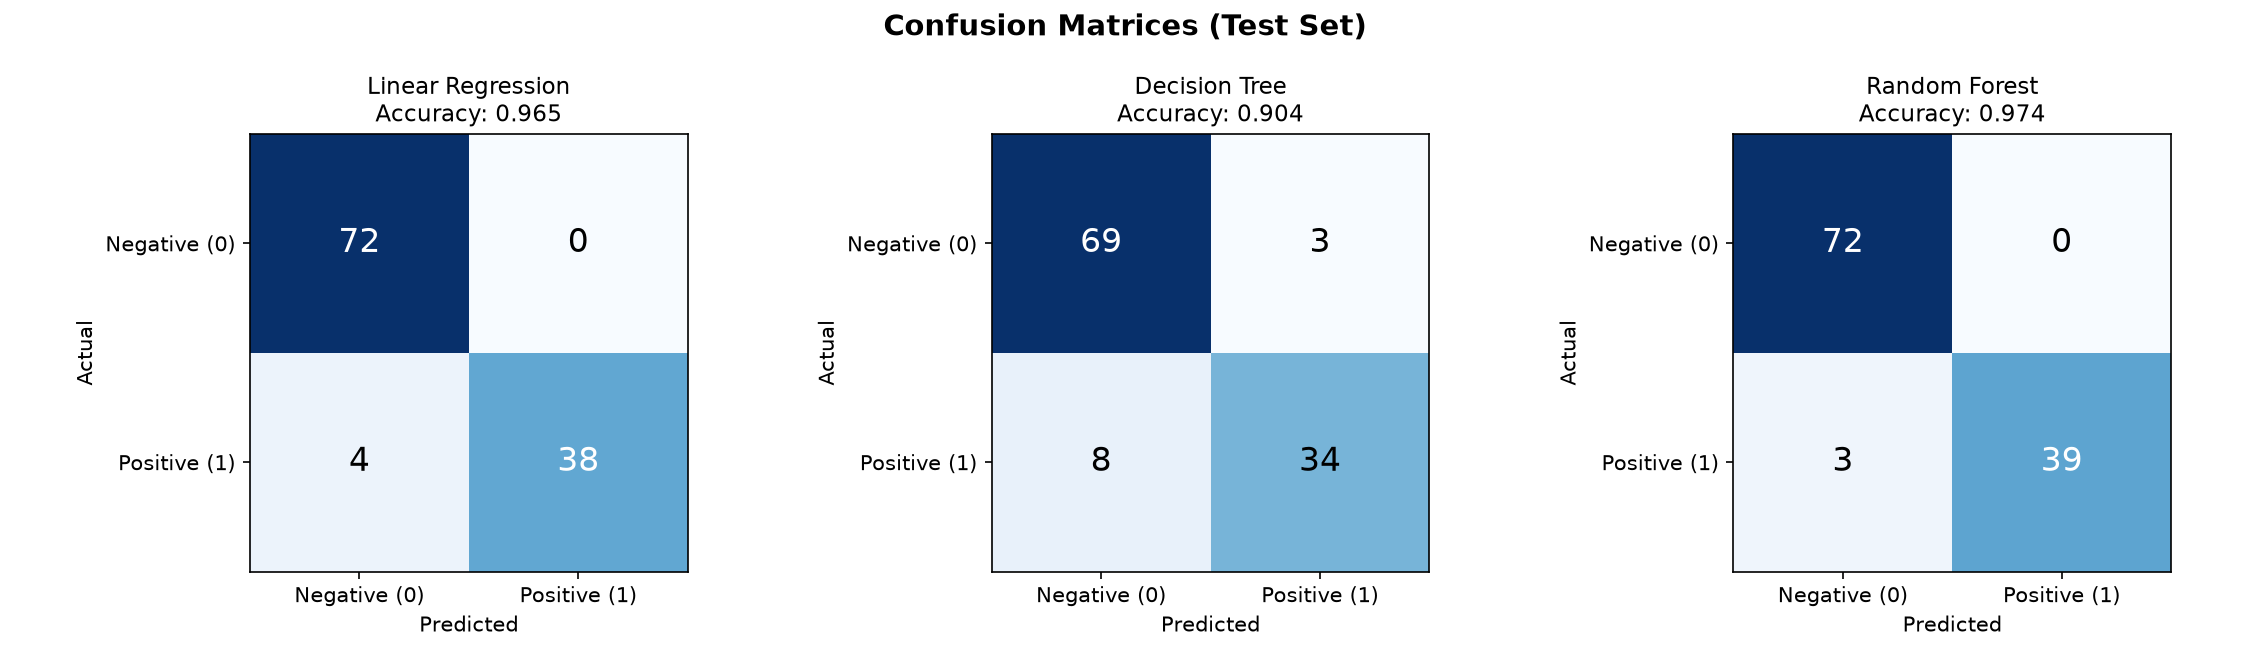

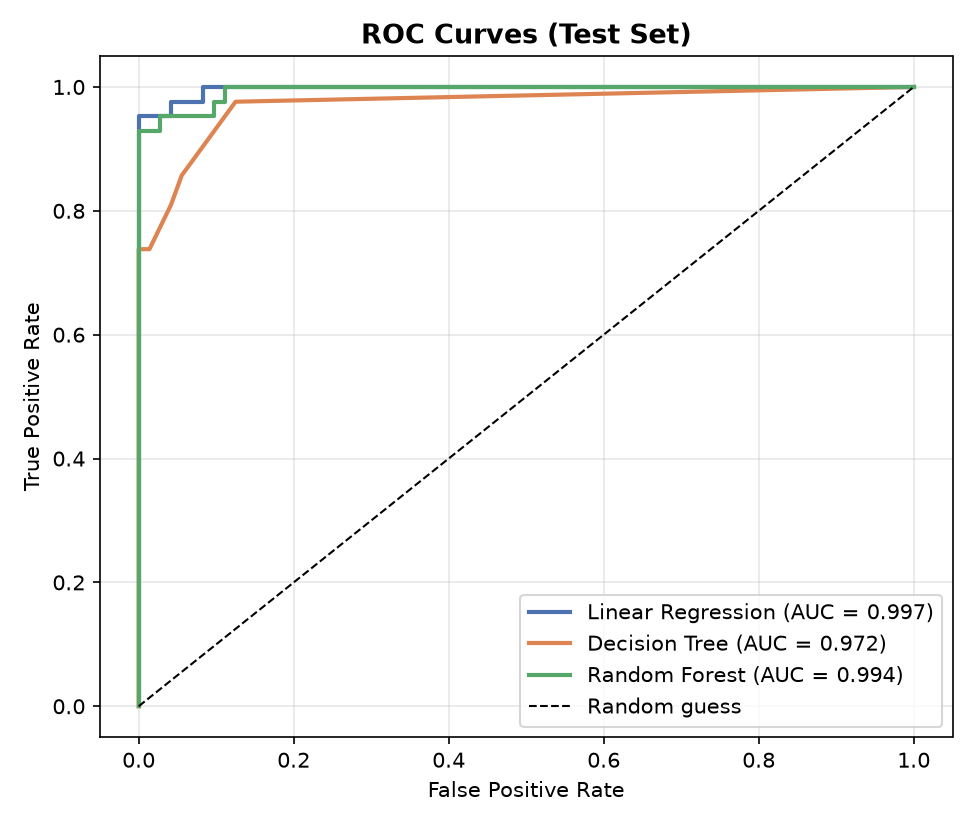

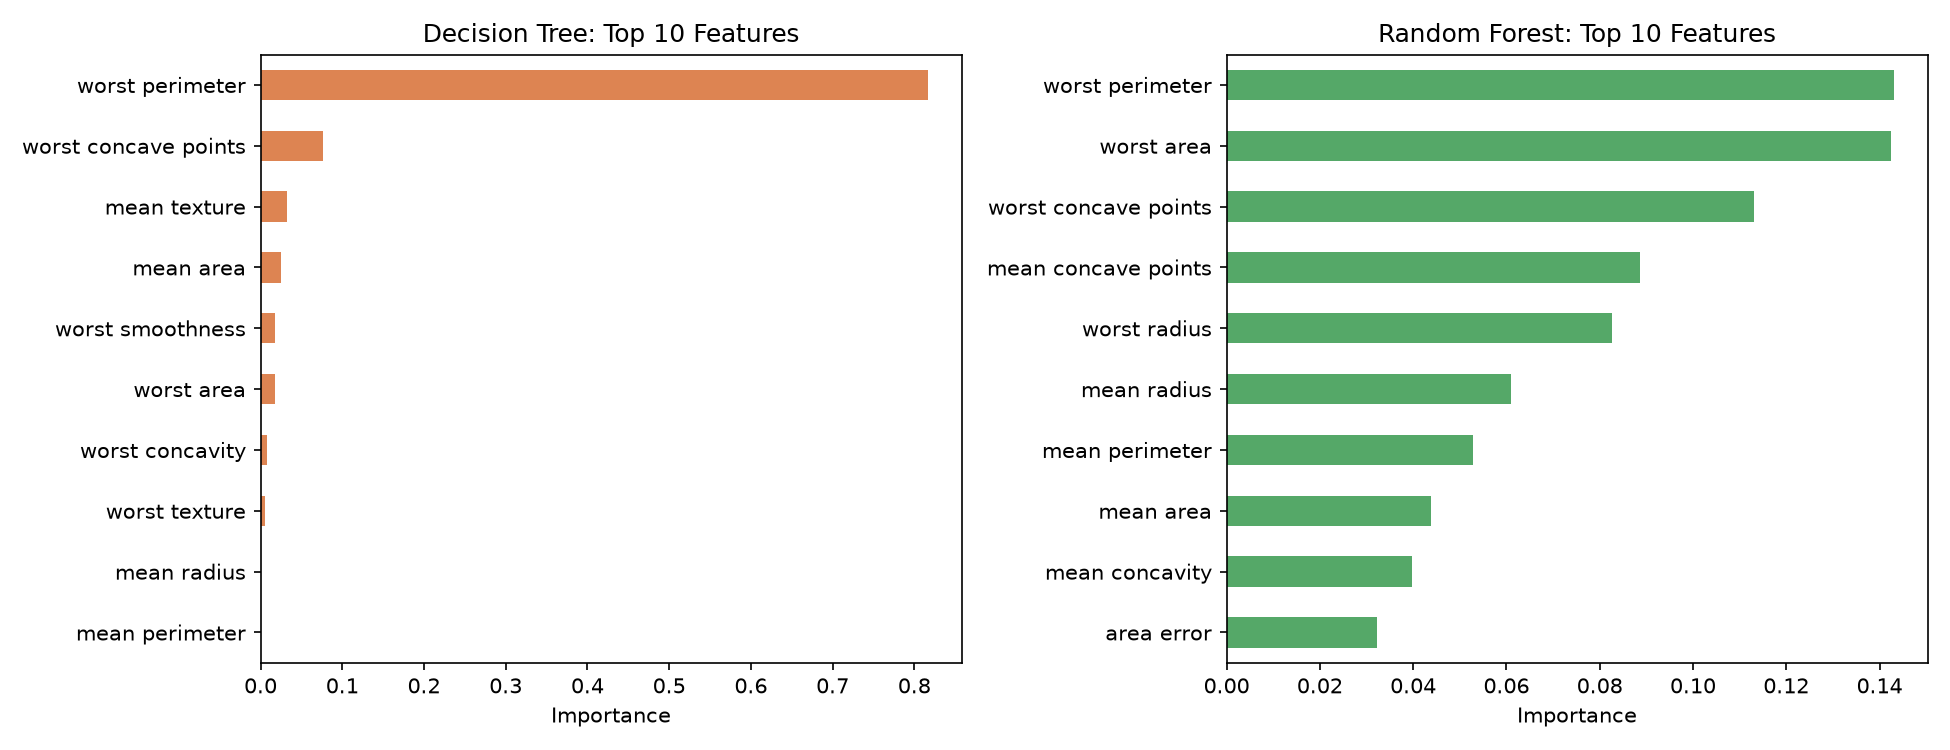

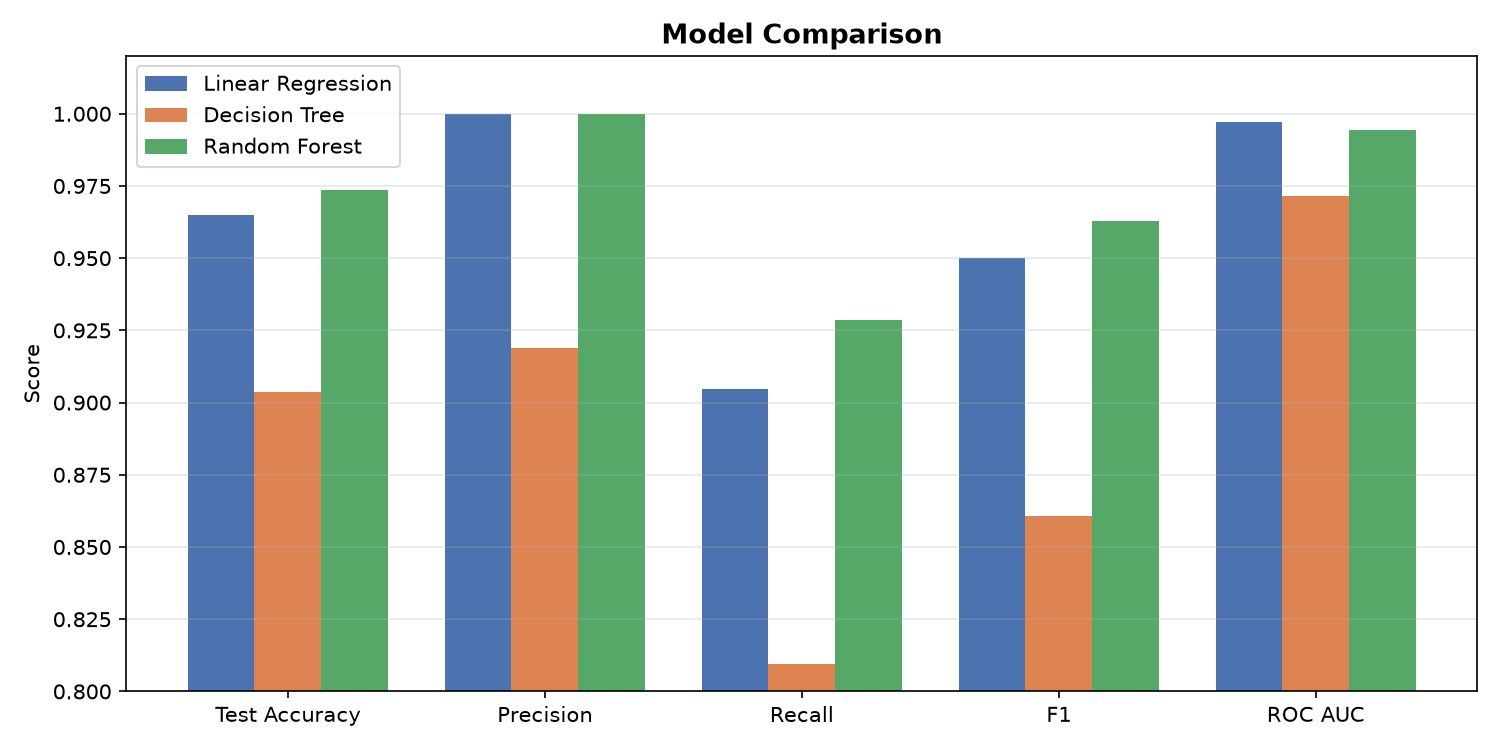

In [5]:
"""
Predictive Modeling Using Machine Learning
Linear Regression, Decision Tree, Random Forest
Train/test accuracy, confusion matrices, ROC curves
"""
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.datasets import load_breast_cancer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    accuracy_score, auc, classification_report, confusion_matrix,
    f1_score, precision_score, recall_score, roc_curve,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
OUT_DIR = "outputs"

# ---------------------------------------------------------------
# SETTINGS: to use your own dataset, set CSV_PATH and TARGET.
# Leave CSV_PATH = None to use the built-in demo dataset.
# ---------------------------------------------------------------
CSV_PATH = None          # e.g. "mydata.csv"
TARGET = None            # e.g. "outcome"
TEST_SIZE = 0.2


# ---------------- 1. Data ----------------
def load_data(csv_path=None, target=None):
    if csv_path:
        df = pd.read_csv(csv_path)
        if target not in df.columns:
            raise SystemExit(f"Target '{target}' not found. Columns: {list(df.columns)}")
        df = df.dropna(subset=[target])
        y = df[target]
        X = pd.get_dummies(df.drop(columns=[target]), drop_first=True)
        X = X.fillna(X.median(numeric_only=True))
        y = pd.Series(pd.factorize(y)[0], index=y.index)
        if y.nunique() != 2:
            raise SystemExit("This script expects a binary outcome (2 classes).")
        return X, y, os.path.basename(csv_path)
    data = load_breast_cancer(as_frame=True)
    return data.data, 1 - data.target, "Breast Cancer (sklearn)"


# ---------------- 2. Models ----------------
class LinearRegressionClassifier(ClassifierMixin, BaseEstimator):
    """Linear Regression on the 0/1 outcome, thresholded at 0.5."""

    def __init__(self, threshold=0.5):
        self.threshold = threshold

    def fit(self, X, y):
        self.classes_ = np.unique(y)
        self.model_ = LinearRegression().fit(X, y)
        return self

    def decision_scores(self, X):
        return self.model_.predict(X)

    def predict(self, X):
        return (self.decision_scores(X) >= self.threshold).astype(int)


def build_models():
    return {
        "Linear Regression": LinearRegressionClassifier(),
        "Decision Tree": DecisionTreeClassifier(max_depth=5, min_samples_leaf=5,
                                                random_state=RANDOM_STATE),
        "Random Forest": RandomForestClassifier(n_estimators=300,
                                                random_state=RANDOM_STATE, n_jobs=-1),
    }


def scores_of(model, X):
    if isinstance(model, LinearRegressionClassifier):
        return model.decision_scores(X)
    return model.predict_proba(X)[:, 1]


# ---------------- 3. Train / test / evaluate ----------------
def evaluate(models, X_train, X_test, y_train, y_test):
    rows, fitted, preds, probs = [], {}, {}, {}
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    for name, model in models.items():
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        fpr, tpr, _ = roc_curve(y_test, scores_of(model, X_test))
        cv_acc = cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy")
        rows.append({
            "Model": name,
            "Train Accuracy": accuracy_score(y_train, model.predict(X_train)),
            "Test Accuracy": accuracy_score(y_test, y_pred),
            "CV Accuracy (mean)": cv_acc.mean(),
            "CV Accuracy (std)": cv_acc.std(),
            "Precision": precision_score(y_test, y_pred),
            "Recall": recall_score(y_test, y_pred),
            "F1": f1_score(y_test, y_pred),
            "ROC AUC": auc(fpr, tpr),
        })
        fitted[name], preds[name], probs[name] = model, y_pred, (fpr, tpr)
    return pd.DataFrame(rows).set_index("Model"), fitted, preds, probs


# ---------------- 4. Plots ----------------
COLORS = {"Linear Regression": "#4C72B0", "Decision Tree": "#DD8452", "Random Forest": "#55A868"}


def plot_confusion_matrices(preds, y_test, class_names):
    fig, axes = plt.subplots(1, len(preds), figsize=(5 * len(preds), 4.4))
    for ax, (name, y_pred) in zip(np.atleast_1d(axes), preds.items()):
        cm = confusion_matrix(y_test, y_pred)
        ax.imshow(cm, cmap="Blues")
        ax.set_title(f"{name}\nAccuracy: {accuracy_score(y_test, y_pred):.3f}", fontsize=11)
        ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
        ax.set_xticklabels(class_names); ax.set_yticklabels(class_names)
        ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
        for i in range(2):
            for j in range(2):
                ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=16,
                        color="white" if cm[i, j] > cm.max() / 2 else "black")
    fig.suptitle("Confusion Matrices (Test Set)", fontsize=14, fontweight="bold")
    fig.tight_layout()
    fig.savefig(f"{OUT_DIR}/confusion_matrices.png", dpi=150)
    plt.close(fig)


def plot_roc_curves(probs, results):
    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    for name, (fpr, tpr) in probs.items():
        ax.plot(fpr, tpr, lw=2, color=COLORS[name],
                label=f"{name} (AUC = {results.loc[name, 'ROC AUC']:.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=1, label="Random guess")
    ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
    ax.set_title("ROC Curves (Test Set)", fontsize=13, fontweight="bold")
    ax.legend(loc="lower right"); ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(f"{OUT_DIR}/roc_curves.png", dpi=150)
    plt.close(fig)


def plot_feature_importance(fitted, feature_names, top_n=10):
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    for ax, name in zip(axes, ["Decision Tree", "Random Forest"]):
        imp = pd.Series(fitted[name].feature_importances_, index=feature_names)
        imp.nlargest(top_n).sort_values().plot.barh(ax=ax, color=COLORS[name])
        ax.set_title(f"{name}: Top {top_n} Features")
        ax.set_xlabel("Importance")
    fig.tight_layout()
    fig.savefig(f"{OUT_DIR}/feature_importance.png", dpi=150)
    plt.close(fig)


def plot_model_comparison(results):
    metrics = ["Test Accuracy", "Precision", "Recall", "F1", "ROC AUC"]
    x = np.arange(len(metrics)); w = 0.26
    fig, ax = plt.subplots(figsize=(10, 5))
    for i, name in enumerate(results.index):
        ax.bar(x + (i - 1) * w, results.loc[name, metrics], w, label=name, color=COLORS[name])
    ax.set_xticks(x); ax.set_xticklabels(metrics)
    ax.set_ylim(0.8, 1.02); ax.set_ylabel("Score")
    ax.set_title("Model Comparison", fontsize=13, fontweight="bold")
    ax.legend(); ax.grid(axis="y", alpha=0.3)
    fig.tight_layout()
    fig.savefig(f"{OUT_DIR}/model_comparison.png", dpi=150)
    plt.close(fig)


# ---------------- 5. Run ----------------
def main():
    os.makedirs(OUT_DIR, exist_ok=True)
    X, y, name = load_data(CSV_PATH, TARGET)
    print(f"Dataset: {name} | {X.shape[0]} samples, {X.shape[1]} features")
    print(f"Class balance: {dict(y.value_counts().sort_index())}\n")

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)

    scaler = StandardScaler().fit(X_train)
    X_train_s = pd.DataFrame(scaler.transform(X_train), columns=X.columns, index=X_train.index)
    X_test_s = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)

    results, fitted, preds, probs = evaluate(build_models(), X_train_s, X_test_s, y_train, y_test)

    pd.set_option("display.width", 200)
    print("=== Model Performance ===")
    print(results.round(4).to_string(), "\n")
    for model_name, y_pred in preds.items():
        print(f"--- {model_name} ---")
        print(classification_report(y_test, y_pred, target_names=["Class 0", "Class 1"], digits=3))

    plot_confusion_matrices(preds, y_test, ["Negative (0)", "Positive (1)"])
    plot_roc_curves(probs, results)
    plot_feature_importance(fitted, X.columns)
    plot_model_comparison(results)
    results.round(4).to_csv(f"{OUT_DIR}/results.csv")

    best = results["Test Accuracy"].idxmax()
    print(f"Best model by test accuracy: {best} ({results.loc[best, 'Test Accuracy']:.2%})")
    print(f"Plots and results saved to ./{OUT_DIR}/")


main()

# Show the charts inside the notebook
from IPython.display import Image, display
for f in ["confusion_matrices", "roc_curves", "feature_importance", "model_comparison"]:
    display(Image(f"{OUT_DIR}/{f}.png"))